In [7]:
import os, sys, math, subprocess, getpass
import numpy as np, pandas as pd, scipy.sparse as sp
import networkx as nx, matplotlib.pyplot as plt
from IPython.display import display
from neo4j import GraphDatabase
from sklearn.preprocessing import normalize
from sklearn.neighbors import NearestNeighbors
from tqdm.auto import tqdm

SEED = 42                                   
URI, USER, DB = "neo4j://localhost:7687", "neo4j", "neo4j"
PASSWORD = getpass.getpass("Password Neo4j: ")   

driver = GraphDatabase.driver(URI, auth=(USER, PASSWORD))
driver.verify_connectivity()

def q(cypher, **params):
    """Jalankan Cypher, kembalikan DataFrame."""
    records, _, _ = driver.execute_query(cypher, parameters_=params, database_=DB)
    return pd.DataFrame([r.data() for r in records])

print("Terhubung ke Neo4j, database:", DB)

Password Neo4j:  ········


Terhubung ke Neo4j, database: neo4j


## Subbab 2.1 nomor 1 

In [8]:
df = pd.read_csv("data/events.csv")
df["waktu"] = pd.to_datetime(df["timestamp"], unit="ms")

print(df.shape)
print("Awal :", df["waktu"].min())
print("Akhir:", df["waktu"].max())
print(df["event"].value_counts())
print(df["visitorid"].nunique(), "visitor |", df["itemid"].nunique(), "item")
df.head()

(2756101, 6)
Awal : 2015-05-03 03:00:04.384000
Akhir: 2015-09-18 02:59:47.788000
event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64
1407580 visitor | 235061 item


,timestamp,visitorid,event,itemid,transactionid,waktu
0,1433221332117,257597,view,355908,NaN,2015-06-02 05:02:12.117
1,1433224214164,992329,view,248676,NaN,2015-06-02 05:50:14.164
2,1433221999827,111016,view,318965,NaN,2015-06-02 05:13:19.827
3,1433221955914,483717,view,253185,NaN,2015-06-02 05:12:35.914
4,1433221337106,951259,view,367447,NaN,2015-06-02 05:02:17.106


In [9]:
df.groupby(df["waktu"].dt.to_period("W")).size()

waktu
2015-04-27/2015-05-03     13683
2015-05-04/2015-05-10    133775
2015-05-11/2015-05-17    148861
2015-05-18/2015-05-24    152514
2015-05-25/2015-05-31    141819
2015-06-01/2015-06-07    146445
2015-06-08/2015-06-14    131852
2015-06-15/2015-06-21    145976
2015-06-22/2015-06-28    141688
2015-06-29/2015-07-05    139233
2015-07-06/2015-07-12    161845
2015-07-13/2015-07-19    152243
2015-07-20/2015-07-26    175437
2015-07-27/2015-08-02    144337
2015-08-03/2015-08-09    128559
2015-08-10/2015-08-16    120763
2015-08-17/2015-08-23    126924
2015-08-24/2015-08-30    127810
2015-08-31/2015-09-06    119057
2015-09-07/2015-09-13    138789
2015-09-14/2015-09-20     64491
Freq: W-SUN, dtype: int64

In [4]:
P1_START, P1_END = "2015-05-14", "2015-07-14" 
P2_START, P2_END = "2015-07-14", "2015-09-14"  

assert pd.Timestamp(P1_START) < pd.Timestamp(P1_END) <= pd.Timestamp(P2_START) < pd.Timestamp(P2_END), \
    "Periode harus berurutan dan tidak tumpang tindih (P1 sebelum P2)"
print("Periode valid.")

Periode valid.


## Subbab 2.1 nomor 2

In [10]:
def filter_periode(data, start, end):
    return data[(data["waktu"] >= start) & (data["waktu"] < end)].drop(columns="waktu")

p1 = filter_periode(df, P1_START, P1_END)
p2 = filter_periode(df, P2_START, P2_END)

os.makedirs("data/p1", exist_ok=True)
os.makedirs("data/p2", exist_ok=True)
p1.to_csv("data/p1/events.csv", index=False)     
p2.to_csv("data/p2/events.csv", index=False)     

print("P1:", p1.shape, "| P2:", p2.shape)
print(p1["event"].value_counts(), "\n")
print(p2["event"].value_counts())
assert len(p1) > 0 and len(p2) > 0, "Salah satu periode kosong, ubah periodenya"

P1: (1274033, 5) | P2: (1207800, 5)
event
view           1232775
addtocart        31026
transaction      10232
Name: count, dtype: int64 

event
view           1166474
addtocart        31274
transaction      10052
Name: count, dtype: int64


In [11]:
v1, v2 = set(p1["visitorid"]), set(p2["visitorid"])
beli2 = set(p2.loc[p2["event"] == "transaction", "visitorid"])
print("Visitor P1:", len(v1), "| Visitor P2:", len(v2))
print("Visitor di P1 dan P2     :", len(v1 & v2))
print("Pembeli di P2            :", len(beli2), "| yang juga ada di P1:", len(beli2 & v1))
del df   

Visitor P1: 650722 | Visitor P2: 656167
Visitor di P1 dan P2     : 30561
Pembeli di P2            : 5216 | yang juga ada di P1: 519


## Impor data P1 ke Neo4j

Ubah `RUN_IMPORT = False` bila graf P1 sudah terisi.

In [12]:
RUN_IMPORT = True

if RUN_IMPORT:
    driver.execute_query("MATCH (n) DETACH DELETE n", database_=DB)
    hasil = subprocess.run(
        [sys.executable, "import_events.py", "-p", PASSWORD, "-s", "data/p1", "-d", DB],
        capture_output=True, text=True)
    print(hasil.stdout[-1500:], hasil.stderr[-1500:])

total_rel = int(q("MATCH ()-[r]->() RETURN count(r) AS n")["n"][0])
print("Relasi di graf:", total_rel, "| baris P1:", len(p1))
assert total_rel == len(p1), "Jumlah relasi harus sama dengan jumlah baris P1"

Membaca file data dari: data/p1\events.csv
Memulai proses impor data ke Neo4j...
Proses impor berhasil.
Mengimpor Batch Data: 100%|##########| 255/255 [01:22<00:00,  3.09it/s]

Relasi di graf: 1274033 | baris P1: 1274033


## Subbab 2.1 nomor 3

In [13]:
simpul = q("""
MATCH (n)
RETURN labels(n)[0] AS jenis_simpul, count(*) AS jumlah
ORDER BY jumlah DESC
""")
relasi = q("""
MATCH ()-[r]->()
RETURN type(r) AS jenis_relasi, count(*) AS jumlah
ORDER BY jumlah DESC
""")
display(simpul); display(relasi)

,jenis_simpul,jumlah
0,Visitor,650722
1,Item,168452


,jenis_relasi,jumlah
0,VIEWED,1232775
1,ADDED_TO_CART,31026
2,BOUGHT,10232


Query komposisi subgraf dijalankan melalui Python API menggunakan `driver.execute_query` yang dibungkus dalam fungsi `q()` dengan perintah Cypher `MATCH (n) RETURN labels(n)[0] AS jenis_simpul, count(*) AS jumlah ORDER BY jumlah DESC`. Perintah `MATCH (n)` digunakan untuk mencocokkan seluruh simpul dalam graf, sedangkan `labels(n)[0]` mengambil label pertama setiap simpul sebagai dasar pengelompokan. Selanjutnya, `count(*)` menghitung jumlah simpul berdasarkan label, sementara `ORDER BY jumlah DESC` mengurutkan hasil dari jumlah terbesar hingga terkecil. Berdasarkan hasil query, graf P1 yang mencakup periode 14 Mei hingga 14 Juli 2015 memiliki dua jenis simpul, yaitu Visitor sebanyak 650.722 simpul dan Item sebanyak 168.452 simpul. Dengan demikian, jumlah keseluruhan simpul dalam graf tersebut mencapai 819.174 simpul. Untuk mengetahui komposisi relasi, digunakan query `MATCH ()-[r]->() RETURN type(r) AS jenis_relasi, count(*) AS jumlah ORDER BY jumlah DESC` yang menghitung setiap jenis relasi dan mengurutkannya berdasarkan jumlah terbanyak. Hasilnya menunjukkan bahwa relasi VIEWED berjumlah 1.232.775, ADDED_TO_CART sebanyak 31.026, dan BOUGHT sebanyak 10.232, dengan total 1.274.033 relasi yang sesuai dengan jumlah baris data P1. Berdasarkan komposisi tersebut, graf P1 dapat dikategorikan sebagai graf bipartit berarah yang menghubungkan simpul Visitor dengan simpul Item melalui tiga jenis relasi yang merepresentasikan aktivitas pengguna.

## Subbab 2.1 nomor 4 dan 5

In [14]:
BOBOT = {"VIEWED": 1, "ADDED_TO_CART": 3, "BOUGHT": 5}

edges = q("""
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
RETURN v.visitorId AS u, i.itemId AS i, type(r) AS rel, count(*) AS n
""")
edges["w"] = edges["rel"].map(BOBOT)
pair = edges.groupby(["u", "i"], as_index=False)["w"].max()

user_ids = np.sort(pair["u"].unique())
item_ids = np.sort(pair["i"].unique())
u_idx = pd.Index(user_ids).get_indexer(pair["u"])
i_idx = pd.Index(item_ids).get_indexer(pair["i"])

X = sp.csr_matrix((pair["w"].astype(float), (u_idx, i_idx)),
                  shape=(len(user_ids), len(item_ids)))
print("Matriks User x Item:", X.shape, "| pasangan unik:", X.nnz)

Matriks User x Item: (650722, 168452) | pasangan unik: 986731


In [15]:
def karakter(M, nama, dim_label):
    r, c = M.shape
    d = M.getnnz(axis=1)
    print(f"== {nama} ==")
    print(f"shape = {M.shape} -> {r:,} vektor, tiap vektor berdimensi {c:,} ({dim_label})")
    print(f"nnz = {M.nnz:,} | density = {M.nnz/(r*c):.6%} | sparsity = {1-M.nnz/(r*c):.4%}")
    print(f"elemen non-nol per vektor: rata-rata {d.mean():.2f}, median {np.median(d):.0f}, "
          f"maks {d.max():,}, vektor dengan 1 elemen saja = {np.mean(d==1):.1%}\n")

karakter(X, "VSM User", "jumlah Item")
karakter(X.T.tocsr(), "VSM Item", "jumlah User")

== VSM User ==
shape = (650722, 168452) -> 650,722 vektor, tiap vektor berdimensi 168,452 (jumlah Item)
nnz = 986,731 | density = 0.000900% | sparsity = 99.9991%
elemen non-nol per vektor: rata-rata 1.52, median 1, maks 1,565, vektor dengan 1 elemen saja = 80.0%

== VSM Item ==
shape = (168452, 650722) -> 168,452 vektor, tiap vektor berdimensi 650,722 (jumlah User)
nnz = 986,731 | density = 0.000900% | sparsity = 99.9991%
elemen non-nol per vektor: rata-rata 5.86, median 2, maks 1,302, vektor dengan 1 elemen saja = 41.5%



VSM untuk simpul User dibentuk dengan mengambil data relasi Visitor → Item dari Neo4j yang mencakup VIEWED, ADDED_TO_CART, dan BOUGHT, kemudian menetapkan bobot interaksi masing-masing sebesar 1, 3, dan 5. Apabila satu user memiliki beberapa jenis interaksi dengan item yang sama, bobot tertinggi digunakan untuk merepresentasikan pasangan User–Item tersebut sebelum disusun menjadi matriks sparse menggunakan `scipy.sparse.csr_matrix`. Matriks yang dihasilkan berukuran 650.722 × 168.452, yang berarti terdapat 650.722 vektor user dengan 168.452 dimensi, di mana setiap dimensi mewakili satu item. Matriks tersebut memiliki 986.731 elemen non-nol dengan density sebesar 0,0009% dan sparsity mencapai 99,9991%, sehingga sebagian besar elemennya bernilai nol. Rata-rata setiap user hanya berinteraksi dengan 1,52 item, dengan median 1 dan jumlah maksimum 1.565 item. Selain itu, sebanyak 80% user hanya memiliki satu elemen non-nol, yang menunjukkan terbatasnya informasi interaksi pada sebagian besar vektor user. Visualisasi menggunakan NetworkX menampilkan lima user yang dipilih secara acak dengan seed 42 dari kelompok user yang berinteraksi dengan 3 hingga 15 item agar struktur graf lebih mudah diamati. Dalam visualisasi tersebut, simpul User direpresentasikan dengan warna biru, sedangkan simpul Item berwarna oranye, dengan setiap user terhubung ke item yang pernah berinteraksi dengannya. Dengan demikian, karakteristik VSM User yang berdimensi tinggi tetapi sangat jarang terisi dapat membatasi keandalan pengukuran kemiripan antaruser karena sebagian besar vektor hanya memuat sedikit informasi interaksi.

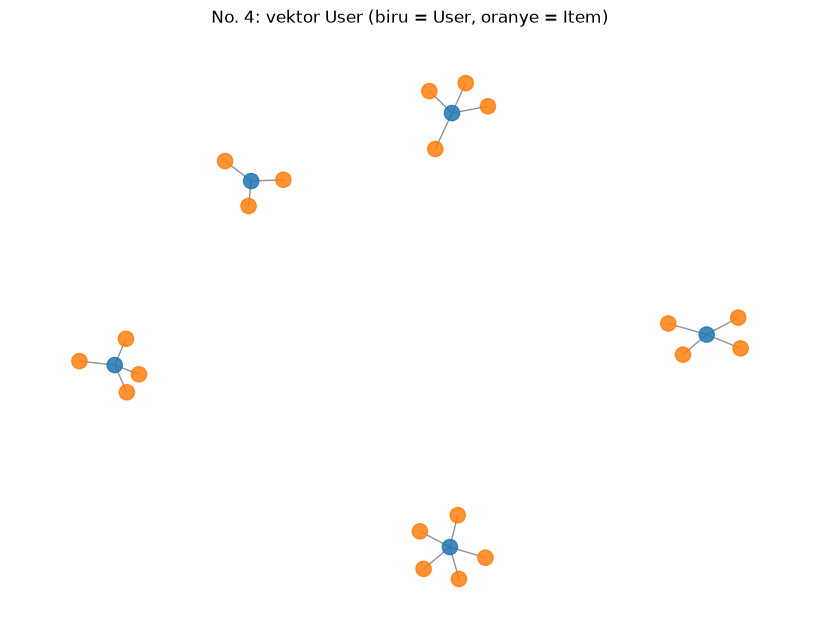

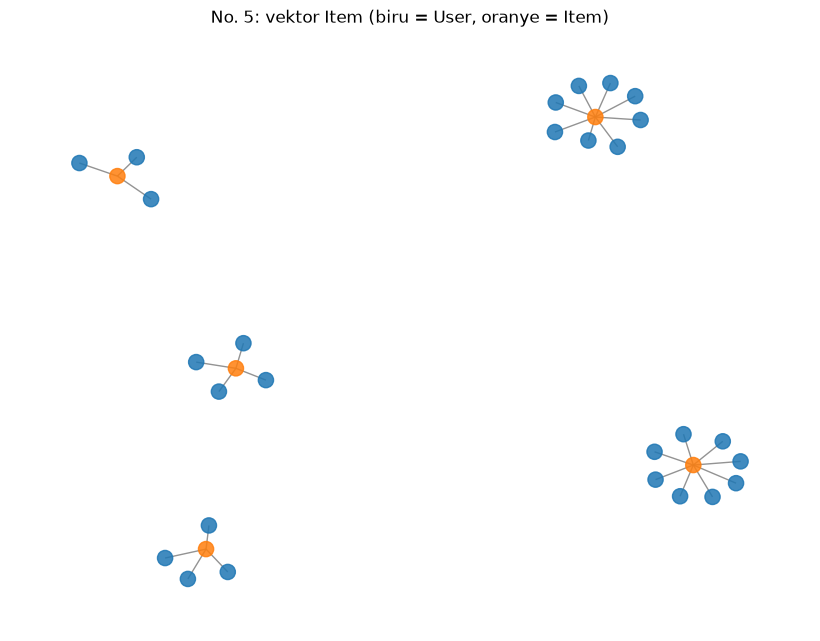

In [16]:
def plot_bipartite(sub, judul):
    G = nx.Graph()
    for u, i in zip(sub["u"], sub["i"]):
        G.add_edge(f"U{u}", f"I{i}")
    warna = ["tab:blue" if n.startswith("U") else "tab:orange" for n in G]
    plt.figure(figsize=(8, 6))
    nx.draw(G, nx.spring_layout(G, seed=SEED), node_color=warna,
            node_size=120, edge_color="gray", alpha=0.85)
    plt.title(judul + " (biru = User, oranye = Item)")
    plt.show()

rng = np.random.default_rng(SEED)
deg_u, deg_i = X.getnnz(axis=1), X.getnnz(axis=0)

kand_u = user_ids[(deg_u >= 3) & (deg_u <= 15)]
pilih_u = rng.choice(kand_u, min(5, len(kand_u)), replace=False)
plot_bipartite(pair[pair["u"].isin(pilih_u)], "No. 4: vektor User")

kand_i = item_ids[(deg_i >= 3) & (deg_i <= 15)]
pilih_i = rng.choice(kand_i, min(5, len(kand_i)), replace=False)
plot_bipartite(pair[pair["i"].isin(pilih_i)], "No. 5: vektor Item")

Berdasarkan hasil eksplorasi pada No. 4 dan 5, proyeksi Item–Item dinilai lebih unggul dibandingkan proyeksi User–User, baik dari segi efisiensi komputasi maupun efektivitas representasi data. Dari aspek efisiensi, proyeksi Item–Item hanya mencakup 168.452 simpul, atau sekitar 3,9 kali lebih sedikit dibandingkan proyeksi User–User yang melibatkan 650.722 simpul. Jumlah maksimum pasangan sisi yang mungkin terbentuk juga lebih rendah, yaitu sekitar 1,4 × 10¹⁰ dibandingkan 2,1 × 10¹¹, dengan estimasi jumlah sisi hasil proyeksi masing-masing sekitar 11,14 juta dan 21,78 juta, sehingga perhitungan similarity pada Item–Item relatif lebih ringan. Dari aspek efektivitas, vektor Item memiliki informasi interaksi yang lebih kaya, dengan rata-rata 5,86 elemen non-nol dan median 2, sedangkan vektor User hanya memiliki rata-rata 1,52 elemen non-nol dan median 1. Selain itu, proporsi simpul dengan hanya satu interaksi pada Item mencapai 41,5%, lebih rendah dibandingkan User yang mencapai 80%, sehingga cosine similarity antaritem berpotensi menghasilkan ukuran kemiripan yang lebih representatif. Proyeksi Item–Item juga menunjukkan stabilitas temporal yang lebih baik karena 88,13% peristiwa pada P2 melibatkan item yang telah muncul di P1, sedangkan pada User proporsinya hanya 9,85%. Oleh karena itu, proyeksi Item–Item lebih sesuai digunakan untuk menghitung kemiripan berdasarkan data P1 dan menerapkannya pada P2 karena lebih efisien serta berpotensi mengurangi dampak masalah cold-start.

## Subbab 2.1 nomor 6

In [17]:
d_u = X.getnnz(axis=1).astype(np.int64)
d_i = X.getnnz(axis=0).astype(np.int64)
est_uu = int((d_i * (d_i - 1) // 2).sum())     # batas atas sisi proyeksi User-User
est_ii = int((d_u * (d_u - 1) // 2).sum())     # batas atas sisi proyeksi Item-Item

nu, ni = len(user_ids), len(item_ids)
perbandingan = pd.DataFrame({
    "proyeksi": ["User-User", "Item-Item"],
    "jumlah simpul": [nu, ni],
    "sisi maks n(n-1)/2": [nu*(nu-1)//2, ni*(ni-1)//2],
    "estimasi sisi (batas atas)": [est_uu, est_ii],
    "% event P2 yang simpulnya ada di P1": [p2["visitorid"].isin(user_ids).mean()*100,
                                             p2["itemid"].isin(item_ids).mean()*100],
})
perbandingan

,proyeksi,jumlah simpul,sisi maks n(n-1)/2,estimasi sisi (batas atas),% event P2 yang simpulnya ada di P1
0,User-User,650722,211719235281,21783130,9.852293
1,Item-Item,168452,14187953926,11142066,88.127919


## Subbab 2.1 nomor 7

In [20]:
Xb = X.copy(); Xb.data[:] = 1.0           
PROYEKSI = "Item-Item"      

if PROYEKSI == "Item-Item":
    M, ids, LABEL, PROP = Xb.T.tocsr(), item_ids, "Item", "itemId"
else:
    M, ids, LABEL, PROP = Xb.tocsr(), user_ids, "Visitor", "visitorId"

MIN_DEG, K_SIM, REF_MIN_DEG = 5, 5, 20
deg = np.diff(M.indptr)
keep = np.where(deg >= MIN_DEG)[0]
Mk = normalize(M[keep], norm="l2", axis=1).tocsr()
MkT = Mk.T.tocsr()
print(f"{PROYEKSI}: {len(keep):,} simpul diproses dari {len(ids):,}")

def topk_cosine(Mk, MkT, k=5, chunk=500):
    rows = []
    for s in tqdm(range(0, Mk.shape[0], chunk)):
        e = min(s + chunk, Mk.shape[0])
        S = (Mk[s:e] @ MkT).tocsr()
        for r in range(e - s):
            a, b = S.indptr[r], S.indptr[r + 1]
            idx, val = S.indices[a:b], S.data[a:b]
            m = idx != (s + r)                          
            idx, val = idx[m], val[m]
            if val.size == 0:
                continue
            top = np.lexsort((idx, -val))[:k]           
            rows += [(int(ids[keep[s + r]]), int(ids[keep[idx[t]]]), float(val[t])) for t in top]
    return pd.DataFrame(rows, columns=["a", "b", "score"])

sim = topk_cosine(Mk, MkT, K_SIM)
sim["score"] = sim["score"].round(6)
print("Pasangan similarity:", sim.shape)
sim.head()

Item-Item: 44,937 simpul diproses dari 168,452


  0%|          | 0/90 [00:00<?, ?it/s]

Pasangan similarity: (172604, 3)


,a,b,score
0,6,118177,0.143223
1,6,266999,0.115470
2,6,274699,0.115470
3,6,397335,0.115470
4,6,453546,0.115470


In [21]:
driver.execute_query("MATCH ()-[s:SIMILAR_TO]->() DELETE s", database_=DB)
sebelum = q("MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah ORDER BY relasi")
sebelum

,relasi,jumlah
0,ADDED_TO_CART,31026
1,BOUGHT,10232
2,VIEWED,1232775


## Subbab 2.1 nomor 7a

In [22]:
rng = np.random.default_rng(SEED)
kandidat = ids[keep][deg[keep] >= REF_MIN_DEG]
REF = int(rng.choice(kandidat))
print(f"Record acuan ({LABEL}.{PROP}) =", REF)

CY_TOP5 = {
"Item-Item": """
MATCH (a:Item {itemId: $ref})<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(h:Visitor)
WITH a, collect(DISTINCT h) AS ha
UNWIND ha AS h
MATCH (h)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(b:Item) WHERE b <> a
WITH a, ha, b, count(DISTINCT h) AS common
MATCH (b)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(hb:Visitor)
WITH a, ha, b, common, count(DISTINCT hb) AS nb WHERE nb >= $min_deg
RETURN b.itemId AS tetangga, common, nb,
       toFloat(common) / sqrt(size(ha) * nb) AS cosine
ORDER BY cosine DESC, tetangga ASC LIMIT 5
""",
"User-User": """
MATCH (a:Visitor {visitorId: $ref})-[:VIEWED|ADDED_TO_CART|BOUGHT]->(h:Item)
WITH a, collect(DISTINCT h) AS ha
UNWIND ha AS h
MATCH (h)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(b:Visitor) WHERE b <> a
WITH a, ha, b, count(DISTINCT h) AS common
MATCH (b)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(hb:Item)
WITH a, ha, b, common, count(DISTINCT hb) AS nb WHERE nb >= $min_deg
RETURN b.visitorId AS tetangga, common, nb,
       toFloat(common) / sqrt(size(ha) * nb) AS cosine
ORDER BY cosine DESC, tetangga ASC LIMIT 5
"""}

top5_cypher = q(CY_TOP5[PROYEKSI], ref=REF, min_deg=MIN_DEG)
display(top5_cypher)

# Validasi: hasil Python dan Cypher harus (hampir) sama
cek = sim[sim["a"] == REF].merge(top5_cypher, left_on="b", right_on="tetangga")
print("Cocok:", len(cek), "dari 5 | selisih maks:", (cek["score"] - cek["cosine"]).abs().max())

Record acuan (Item.itemId) = 45237


,tetangga,common,nb,cosine
0,331381,10,21,0.412393
1,348804,5,9,0.314970
2,15153,5,12,0.272772
3,431232,5,13,0.262071
4,33425,3,5,0.253546


Cocok: 5 dari 5 | selisih maks: 3.941743559887634e-07


## Subbab 2.1 nomor 7b

In [23]:
CY_WRITE = f"""
UNWIND $rows AS r
MATCH (a:{LABEL} {{{PROP}: r.a}}), (b:{LABEL} {{{PROP}: r.b}})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = r.score, s.metode = 'cosine-biner', s.periode = 'P1'
"""
rows = sim.to_dict("records")
for s in tqdm(range(0, len(rows), 5000)):
    driver.execute_query(CY_WRITE, parameters_={"rows": rows[s:s+5000]}, database_=DB)

print("Query penulisan:", CY_WRITE)
q(f"""
MATCH (a:{LABEL} {{{PROP}: $ref}})-[s:SIMILAR_TO]->(b:{LABEL})
RETURN a.{PROP} AS acuan, b.{PROP} AS tetangga, s.score AS score
ORDER BY score DESC, tetangga ASC LIMIT 5
""", ref=REF)

  0%|          | 0/35 [00:00<?, ?it/s]

Query penulisan: 
UNWIND $rows AS r
MATCH (a:Item {itemId: r.a}), (b:Item {itemId: r.b})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = r.score, s.metode = 'cosine-biner', s.periode = 'P1'



,acuan,tetangga,score
0,45237,331381,0.412393
1,45237,348804,0.314970
2,45237,15153,0.272772
3,45237,431232,0.262071
4,45237,33425,0.253546


Berdasarkan hasil eksplorasi No. 6, proyeksi yang digunakan adalah Item–Item, dengan membentuk matriks biner User × Item yang kemudian ditransposisikan menjadi Item × User dan dinormalisasi menggunakan L2 pada setiap baris sebelum perhitungan cosine similarity dilakukan melalui perkalian matriks sparse per chunk berukuran 500 baris. Perhitungan dibatasi pada 44.937 item dengan derajat minimal 5, kemudian diambil lima tetangga teratas untuk setiap item sehingga menghasilkan 172.604 pasangan kemiripan. Sebagai pengujian, dipilih item acuan 45237 secara acak dan reproducible menggunakan `default_rng(42)` dari kelompok item dengan derajat minimal 20, yang tercatat telah dikunjungi oleh 28 visitor, lalu lima tetangga terdekatnya dihitung menggunakan query Cypher berdasarkan jumlah visitor yang sama-sama mengakses kedua item dan total visitor masing-masing item. Hasil perhitungan menunjukkan bahwa lima tetangga teratas adalah item 331381 dengan cosine similarity 0,412393, item 348804 sebesar 0,314970, item 15153 sebesar 0,272772, item 431232 sebesar 0,262071, dan item 33425 sebesar 0,253546, serta seluruh hasil tersebut sesuai dengan perhitungan Python dengan kecocokan 5 dari 5 dan selisih maksimum 3,9 × 10⁻⁷. Selanjutnya, seluruh nilai kemiripan disimpan kembali ke dalam graf Neo4j sebagai relasi berarah `SIMILAR_TO` menggunakan operasi `MERGE` secara bertahap dengan ukuran batch 5.000 baris untuk mencegah duplikasi, disertai atribut skor, metode `cosine-biner`, dan periode `P1`. Proses tersebut menghasilkan 172.604 relasi `SIMILAR_TO`, yang kemudian diverifikasi melalui query pembacaan kembali terhadap item acuan 45237. Hasil verifikasi menampilkan lima item tetangga dengan skor kemiripan yang identik dengan hasil perhitungan sebelumnya, sehingga mengonfirmasi konsistensi antara perhitungan cosine similarity di Python dan penyimpanan relasi pada Neo4j.

## Subbab 2.1 nomor 8

In [24]:
sesudah = q("MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah ORDER BY relasi")
perbandingan_no8 = sebelum.merge(sesudah, on="relasi", how="outer",
                                  suffixes=("_sebelum", "_sesudah")).fillna(0)
perbandingan_no8

,relasi,jumlah_sebelum,jumlah_sesudah
0,ADDED_TO_CART,31026.0,31026
1,BOUGHT,10232.0,10232
2,SIMILAR_TO,0.0,172604
3,VIEWED,1232775.0,1232775


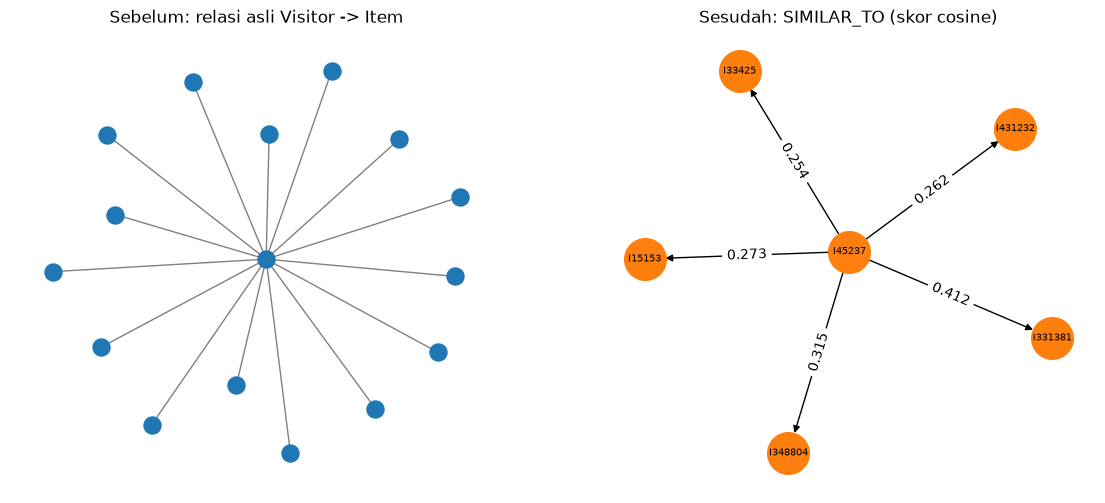

In [25]:
top5 = sim[sim["a"] == REF].sort_values("score", ascending=False).head(5)

if PROYEKSI == "Item-Item":
    asal = q("""MATCH (v:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item {itemId:$ref})
                RETURN DISTINCT v.visitorId AS x LIMIT 15""", ref=REF)
    G1 = nx.Graph([(f"V{x}", f"I{REF}") for x in asal["x"]])
else:
    asal = q("""MATCH (v:Visitor {visitorId:$ref})-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
                RETURN DISTINCT i.itemId AS x LIMIT 15""", ref=REF)
    G1 = nx.Graph([(f"V{REF}", f"I{x}") for x in asal["x"]])

G2 = nx.DiGraph()
pref = "I" if PROYEKSI == "Item-Item" else "V"
for _, r in top5.iterrows():
    G2.add_edge(f"{pref}{REF}", f"{pref}{int(r['b'])}", w=round(r["score"], 3))

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
nx.draw(G1, nx.spring_layout(G1, seed=SEED), ax=ax[0], node_size=150,
        node_color="tab:blue", edge_color="gray")
ax[0].set_title("Sebelum: relasi asli Visitor -> Item")
pos = nx.spring_layout(G2, seed=SEED)
nx.draw(G2, pos, ax=ax[1], with_labels=True, node_size=900, node_color="tab:orange", font_size=7)
nx.draw_networkx_edge_labels(G2, pos, nx.get_edge_attributes(G2, "w"), ax=ax[1])
ax[1].set_title("Sesudah: SIMILAR_TO (skor cosine)")
plt.show()